In [1]:
import matplotlib.pyplot as plt
import numpy as np  
import pandas as pd
import scipy
import os,sys,matplotlib 
import seaborn as sns
from statannotations.Annotator import Annotator

# loading my SC
sys.path.append(os.path.abspath(".."))

from func_analysis import node_strength,corr
from func_plot import plt_setting,style_axis,min_max_rescale,plot_scatter

In [2]:
if_save_fig = False
plt_setting(plt)

In [3]:
# ctx_labels is stored as an object array.
with np.load("../prepare_SC_EC_FC.npz", allow_pickle=True) as data:
    ctx_labels = data["ctx_labels"]
    sc_ctx = data["sc_ctx"]
    fc_ctx = data["fc_ctx"]
    ftract_ctx = data["ftract_ctx"]
    hierarchyID = data["hierarchyID_plt"]
    hierarchy = data["hierarchy"]

# num of nodes
N = len(ctx_labels)

In [4]:
S=np.copy(sc_ctx) # SC
S=S/S.max() # SC除以最大值标准化

E=np.copy(ftract_ctx)
E[np.diag_indices_from(E)]=np.nan # EC 对角元素去掉

F=np.copy(np.tanh(fc_ctx)) # 将fisher z-score 之后的FC转换回R值
F[np.diag_indices_from(F)]=np.nan # FC 对角元素去掉
print(np.nanmax(F))

0.891101127383349


In [5]:
# Create a matrix with ones,Set the lower triangle to NaN
mask_tril = np.ones((N, N))
mask_tril[np.tril_indices(N, 0)] = np.nan

mask_diag = np.ones((N, N))
mask_diag[np.diag_indices_from(mask_diag)] = np.nan

In [6]:
# load parameters
trained_w=np.random.randn(68)
trained_I=np.random.randn(68)
trained_sigma=np.random.randn(68)

# SC,EC,FC NodeStrength 

In [7]:
NS_ECeff,NS_ECaff=node_strength(E)
NS_FC,_=node_strength(F)
NS_SC,_=node_strength(S)

if if_save_fig: np.savez('./Analysis_node_strength/Analysis_node_strength.npz', NS_ECeff=NS_ECeff, NS_ECaff=NS_ECaff, NS_FC=NS_FC, NS_SC=NS_SC)

/data/xyc/codes/xyc_github/EC-FC-BPTT-DecoModel/func_analysis.py:93: RuntimeWarning: Mean of empty slice
  NS_eff = np.nanmean(x,axis=-2) #按行计算求和，得到列的性质（最后第二维）：EC上刺激某节点，其他节点的平均响应（出度）efferent
/data/xyc/codes/xyc_github/EC-FC-BPTT-DecoModel/func_analysis.py:94: RuntimeWarning: Mean of empty slice
  NS_aff = np.nanmean(x,axis=-1) #按列计算求和，得到行的性质（最后第一维）：EC某节点的在刺激所有其他节点时的平均响应（入度）afferent


In [8]:
ctx_labels[np.isnan(NS_ECaff)]

array(['ctx-lh-bankssts', 'ctx-lh-frontalpole', 'ctx-lh-temporalpole',
       'ctx-rh-bankssts', 'ctx-rh-frontalpole', 'ctx-rh-temporalpole'],
      dtype=object)

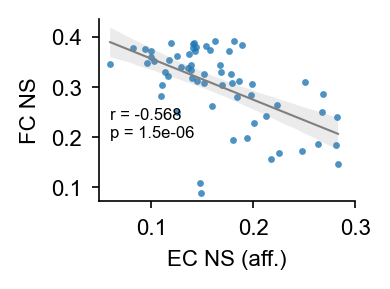

In [9]:
_,ax=plt.subplots(1,1,figsize=(42/25.4, 30/25.4))

style_axis(ax)


plot_scatter(ax,NS_ECaff,NS_FC,(.06,.2))
ax.set_xlabel('EC NS (aff.)')
ax.set_ylabel('FC NS')
ax.set_xticks([.1,.2,.3])

if if_save_fig: plt.savefig('./Analysis_node_strength/fig4_scatter_NS.svg')

# NodeStrength vs. Hierarchy

In [10]:
def plot_scatter(ax,x,y,text_xy=None,mask=None, label='',markersize=6,alphaline=1,cmap=plt.colormaps['tab10']):
    if mask is None:
        mask=(~np.isnan(x))&(~np.isnan(y))
    x=np.copy(x[mask])
    y=np.copy(y[mask])
    sns.regplot(ax=ax,x=x,y=y,label=label,scatter_kws={'s':markersize,'linewidth':0},line_kws={"color": cmap(7),'alpha':alphaline})
    
    r,p=scipy.stats.pearsonr(x, y)
    if p>0.05:
        text="r = {:.3f}\np = {:.3f} (n.s.)".format(r,p)
    elif p<0.001:
        text="r = {:.3f}\np = {:.1e}".format(r,p)
    else:
        text="r = {:.3f}\np = {:.3f}".format(r,p)
    if text_xy is None:
        text_xy0=1.1*x.min()
        text_xy1=0.8*y.max()
        ax.text(text_xy0,text_xy1,text)
    else:
        ax.text(text_xy[0],text_xy[1],text)

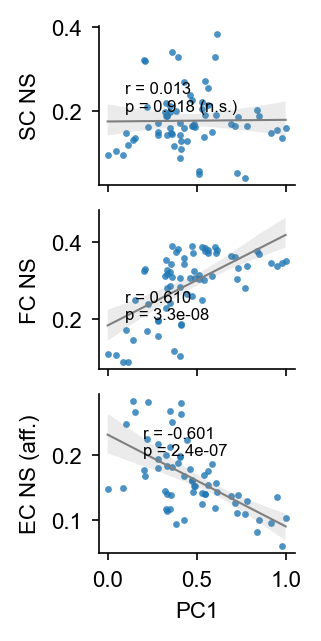

In [11]:
_,axs=plt.subplots(3,1,figsize=(40/25.4, 27*3/25.4))

for ax in axs.flat: style_axis(ax);ax.set_xticks([0,.5,1])

i=3
h = min_max_rescale(hierarchy[:,i])
h_name = hierarchyID[i]

ax=axs[0]
plot_scatter(ax,h,NS_SC,(.1,.2))
ax.set_ylabel('SC NS')
ax.set_xticklabels([])
# ax.set_xlabel(h_name)

ax=axs[1]
plot_scatter(ax,h,NS_FC,(.1,.2))
ax.set_ylabel('FC NS')
ax.set_xticklabels([])
# ax.set_xlabel(h_name)

ax=axs[2]
plot_scatter(ax,h,NS_ECaff,(.2,.2))
ax.set_ylabel('EC NS (aff.)')
ax.set_xlabel(h_name)

plt.tight_layout()

if if_save_fig: plt.savefig('./Analysis_node_strength/fig4_scatter_NS_SST.svg')

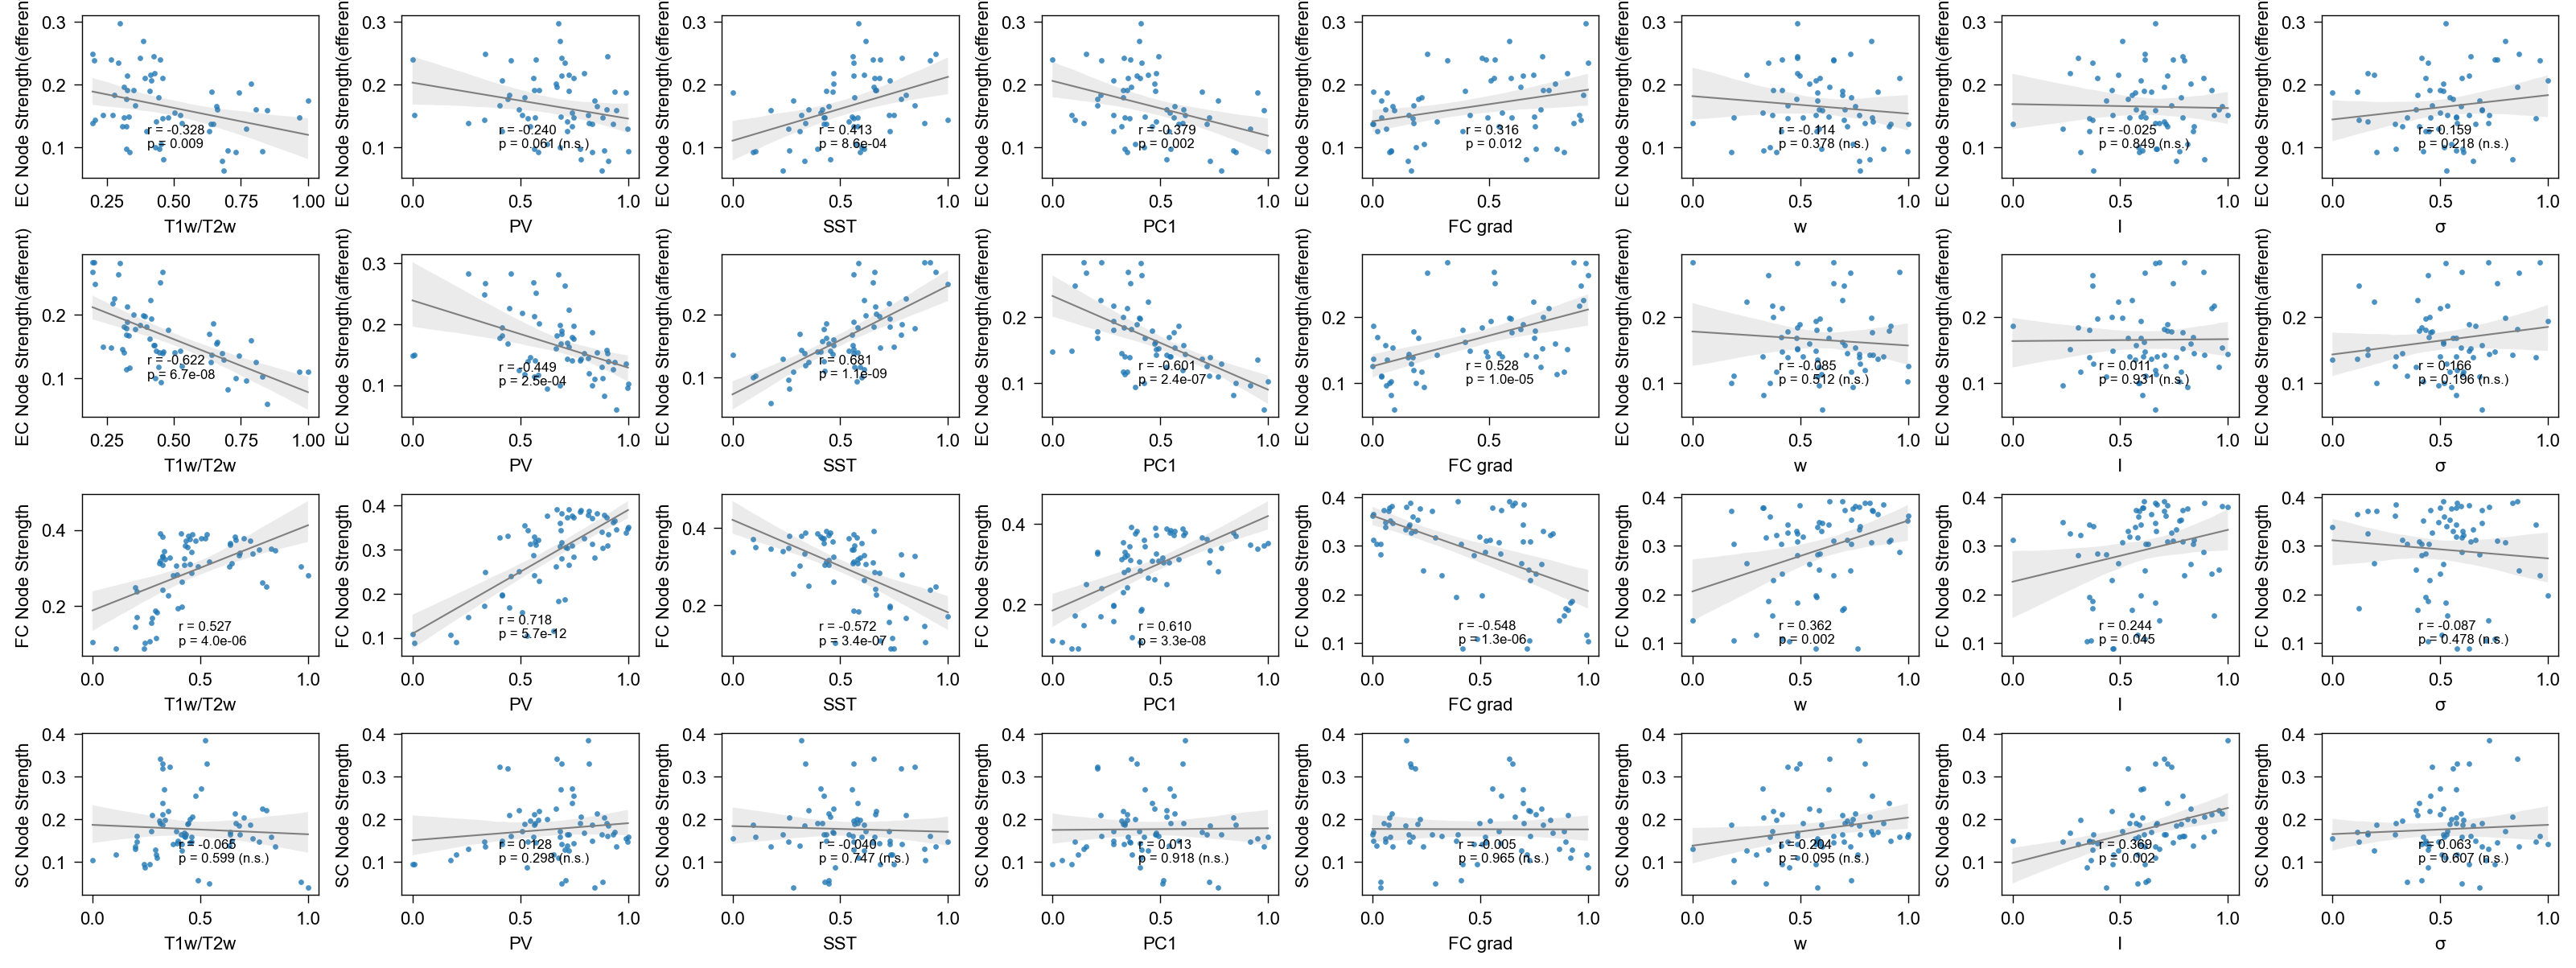

In [12]:
All_P = np.concatenate((hierarchy, np.hstack((trained_w[:,None],trained_I[:,None],trained_sigma[:,None])) ),axis=1)
IDs_P = np.concatenate((hierarchyID, np.asarray(['w','I','σ'])))

_,axs=plt.subplots(4,IDs_P.size,figsize=(2*IDs_P.size,1.5*4,))

for i in range(IDs_P.size):

    P=min_max_rescale(All_P[:,i])
    name=IDs_P[i]
    
    text_xy = (.4,.1)

    ax1=axs[0,i]
    plot_scatter(ax1,P,NS_ECeff,text_xy=text_xy)
    ax1.set_ylabel('EC Node Strength(efferent)')
    ax1.set_xlabel(name)

    ax2=axs[1,i]
    plot_scatter(ax2,P,NS_ECaff,text_xy=text_xy)
    ax2.set_ylabel('EC Node Strength(afferent)')
    ax2.set_xlabel(name)

    ax3=axs[2,i]
    plot_scatter(ax3,P,NS_FC,text_xy=text_xy)
    ax3.set_ylabel('FC Node Strength')
    ax3.set_xlabel(name)

    ax3=axs[3,i]
    plot_scatter(ax3,P,NS_SC,text_xy=text_xy)
    ax3.set_ylabel('SC Node Strength')
    ax3.set_xlabel(name)

plt.tight_layout()

PV


array([0.70968125, 0.33794883, 0.79579422, 0.99879052, 0.        ,
       0.52000757, 0.7782245 , 0.54596436, 0.66693955, 0.87880349,
       0.56429565, 0.89028914, 0.44722895, 0.58410069, 0.41599645,
       0.83207166, 0.68268031, 0.67708874, 0.72618085, 1.        ,
       0.93830941, 0.57338592, 0.8547511 , 0.74714679, 0.33412312,
       0.68888616, 0.6911041 , 0.81950197, 0.62451265, 0.7252393 ,
       0.53065889, 0.17814173, 0.88135877, 0.44164447, 0.69295211,
       0.45631048, 0.90412091, 0.98872544, 0.008113  , 0.53555169,
       0.78108795, 0.56804989, 0.49297168, 0.90728743, 0.58756945,
       0.83251114, 0.51018503, 0.56639137, 0.41599645, 0.71796971,
       0.69255689, 0.70677469, 0.74578722, 0.94568462, 0.92973492,
       0.55953228, 0.89894659, 0.73941808, 0.25832499, 0.74049284,
       0.66928351, 0.81404129, 0.68230419, 0.7192495 , 0.65332822,
       0.20085391, 0.84478829, 0.40392396])

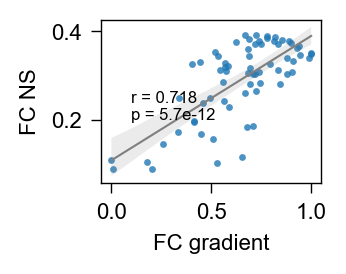

In [13]:
_,ax=plt.subplots(figsize=(36/25.4, 27/25.4))

i=1
h = min_max_rescale(hierarchy[:,i])
h_name = hierarchyID[i]
print(h_name)

plot_scatter(ax,h,NS_FC,(.1,.2))
ax.set_ylabel('FC NS')
ax.set_xlabel('FC gradient')

if if_save_fig: plt.savefig('./Analysis_node_strength/figS_scatter_NSFC_FCgrad.svg')

h

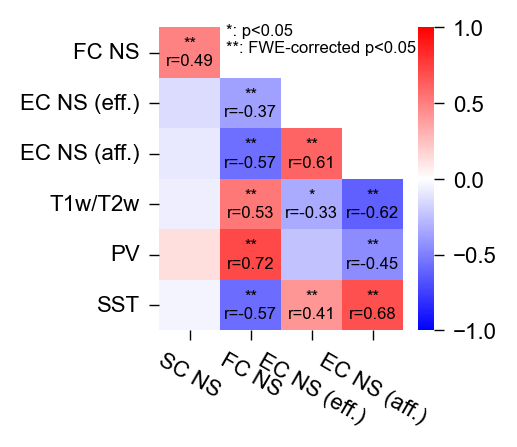

In [14]:
# heatmap
All_P = np.hstack((
    NS_SC[:,None],
    NS_FC[:,None],
    NS_ECeff[:,None],
    NS_ECaff[:,None],
    hierarchy[:,hierarchyID=='T1w/T2w'],
    hierarchy[:,hierarchyID=='PV'],
    hierarchy[:,hierarchyID=='SST'],))
IDs_P = np.asarray(['SC NS','FC NS','EC NS (eff.)','EC NS (aff.)','T1w/T2w','PV','SST',])

def corr_df(X,IDs_X,Y,IDs_Y):
    R=np.zeros((X.shape[1],Y.shape[1]))
    P=np.zeros((X.shape[1],Y.shape[1]))
    for i in range(X.shape[1]):
        for j in range(Y.shape[1]):
            x=X[:,i]
            y=Y[:,j]
            mask=(~np.isnan(x))&(~np.isnan(y))
            x=np.copy(x[mask])
            y=np.copy(y[mask])
            r=scipy.stats.pearsonr(x, y).statistic
            p=scipy.stats.pearsonr(x, y).pvalue
            R[i,j]=r
            P[i,j]=p

    R[np.triu_indices_from(R,1)]=np.nan
    P[np.triu_indices_from(R,1)]=np.nan
    Rdf = pd.DataFrame(R,columns=IDs_Y,index=IDs_X)
    Pdf = pd.DataFrame(P,columns=IDs_Y,index=IDs_X)

    stat=np.empty((X.shape[1],Y.shape[1]),dtype=object)
    for i in range(X.shape[1]):
        for j in range(Y.shape[1]):
            if P[i,j] < (0.05/18):
                stat[i,j]='**\nr={:.2f}'.format(R[i,j])
            elif P[i,j] < 0.05:
                stat[i,j]='*\nr={:.2f}'.format(R[i,j])
            else:
                stat[i,j]=''
    statsdf = pd.DataFrame(stat,columns=IDs_Y,index=IDs_X)

    return R,P,Rdf,Pdf,statsdf

R,P,Rdf,Pdf,statsdf=corr_df(All_P[:,1:],IDs_P[1:],All_P[:,:4],IDs_P[:4])

fig,ax=plt.subplots(figsize=(50/25.4, 50/25.4))

vmax=np.abs(Rdf.values).max()
sns.heatmap(Rdf,ax=ax,cmap='bwr',vmin=-1,vmax=1,annot=statsdf,fmt="",annot_kws={"color":'k',})
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_xticklabels(ax.get_xticklabels(), rotation=-30)

ax.text(1.1,0.5, '*: p<0.05\n**: FWE-corrected p<0.05')

if if_save_fig: plt.savefig('./Analysis_node_strength/fig4_heatmap.svg')